Labels

Build the month-end decision grid and the forward-return labels (1, 3 and 6 months).
Input is `data/processed/panel.csv` from notebook 01.
Outputs are `data/processed/labels.csv` and `data/processed/benchmark_ew.csv`.

## Setup

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

# src is one folder up from notebooks, so add that folder so the import works
sys.path.append("..")
from src.data import load_data
from src.labels import get_decision_dates, make_month_end_prices, make_forward_returns

PANEL_PATH = "../data/processed/panel.csv"
LABELS_PATH = "../data/processed/labels.csv"
BENCHMARK_PATH = "../data/processed/benchmark_ew.csv"

## 1. Load panel and build decision dates

In [2]:
# load_data reads the csv, parses dates and sorts by Ticker then Date
panel = load_data(PANEL_PATH)

decision_dates = get_decision_dates(panel)

print("number of decision dates:", len(decision_dates))
print("first decision date:", decision_dates[0].date())
print("last decision date:", decision_dates[-1].date())
print("last date in panel:", panel["Date"].max().date(), "(sept 2026 is incomplete so it should be dropped)")

number of decision dates: 92
first decision date: 2019-01-31
last decision date: 2026-08-31
last date in panel: 2026-09-18 (sept 2026 is incomplete so it should be dropped)


## 2. Month-end prices (wide table)

In [3]:
month_end_prices = make_month_end_prices(panel, decision_dates)

# rows should be decision dates, columns should be the 30 tickers
print("month-end prices shape (dates, tickers):", month_end_prices.shape)
print()
print(month_end_prices.head())

month-end prices shape (dates, tickers): (92, 30)

Ticker      ASHOKLEY.NS  ASIANPAINT.NS  AUROPHARMA.NS  AXISBANK.NS  \
Date                                                                 
2019-01-31    34.839508    1322.297729     755.323792   718.248352   
2019-02-28    37.067860    1315.370850     683.838196   705.179382   
2019-03-28    37.967773    1401.302490     738.771729   775.891113   
2019-04-30    37.260693    1369.616455     786.598755   762.126404   
2019-05-31    38.074905    1317.336792     645.759155   803.321106   

Ticker      BHARATFORG.NS    CIPLA.NS  COALINDIA.NS  COFORGE.NS  \
Date                                                              
2019-01-31     467.890381  485.698364    119.219020  240.788345   
2019-02-28     486.776825  520.672729    121.156038  242.616211   
2019-03-28     469.456299  493.491241    128.466388  245.050293   
2019-04-30     448.197266  530.484436    137.199478  237.619537   
2019-05-31     443.546722  524.710083    137.934074  240

## 3. Forward returns for 1, 3 and 6 months

In [4]:
fwd_1m_wide = make_forward_returns(month_end_prices, 1)
fwd_3m_wide = make_forward_returns(month_end_prices, 3)
fwd_6m_wide = make_forward_returns(month_end_prices, 6)

# the last few rows should be empty because there is no future price yet
print("last 3 rows of fwd_1m (first 4 tickers):")
print(fwd_1m_wide.iloc[-3:, :4])

last 3 rows of fwd_1m (first 4 tickers):
Ticker      ASHOKLEY.NS  ASIANPAINT.NS  AUROPHARMA.NS  AXISBANK.NS
Date                                                              
2026-06-30     0.053773       0.042342       0.000950    -0.085644
2026-07-31     0.056926      -0.034106       0.086571     0.057340
2026-08-31          NaN            NaN            NaN          NaN


## 4. Convert to long format and merge

In [5]:
# melt turns the wide table (one column per ticker) into one row per (Date, Ticker)
fwd_1m_long = fwd_1m_wide.reset_index().melt(id_vars="Date", var_name="Ticker", value_name="fwd_1m")
fwd_3m_long = fwd_3m_wide.reset_index().melt(id_vars="Date", var_name="Ticker", value_name="fwd_3m")
fwd_6m_long = fwd_6m_wide.reset_index().melt(id_vars="Date", var_name="Ticker", value_name="fwd_6m")

# join the three horizons side by side on (Date, Ticker)
labels = pd.merge(fwd_1m_long, fwd_3m_long, on=["Date", "Ticker"])
labels = pd.merge(labels, fwd_6m_long, on=["Date", "Ticker"])

# same sort order as the rest of the project
labels = labels.sort_values(["Ticker", "Date"])
labels = labels.reset_index(drop=True)

print("labels shape:", labels.shape, "(expected", len(decision_dates) * 30, "rows)")
print()
print(labels.head())

labels shape: (2760, 5) (expected 2760 rows)

        Date       Ticker    fwd_1m    fwd_3m    fwd_6m
0 2019-01-31  ASHOKLEY.NS  0.063960  0.069495 -0.105907
1 2019-02-28  ASHOKLEY.NS  0.024277  0.027168 -0.224621
2 2019-03-28  ASHOKLEY.NS -0.018623 -0.015237 -0.193081
3 2019-04-30  ASHOKLEY.NS  0.021852 -0.164004 -0.081422
4 2019-05-31  ASHOKLEY.NS -0.018008 -0.245129 -0.072956


## 5. Cross-sectional rank of fwd_1m

In [6]:
# rank within each month only, never across months
# pct=True turns rank 1..30 into 1/30..1, so higher = better return that month
labels["fwd_1m_rank"] = labels.groupby("Date")["fwd_1m"].rank(pct=True)

# check one month: min should be about 1/30, max should be 1
example_date = decision_dates[0]
example_month = labels[labels["Date"] == example_date]
print("example month:", example_date.date())
print("min rank:", example_month["fwd_1m_rank"].min())
print("max rank:", example_month["fwd_1m_rank"].max())
print("number of stocks ranked:", example_month["fwd_1m_rank"].notna().sum())

example month: 2019-01-31
min rank: 0.03333333333333333
max rank: 1.0
number of stocks ranked: 30


## 6. Equal-weight benchmark

In [7]:
# average forward return across all 30 stocks on each decision date
benchmark_ew = labels.groupby("Date")[["fwd_1m", "fwd_3m", "fwd_6m"]].mean()
benchmark_ew = benchmark_ew.reset_index()

print("benchmark shape:", benchmark_ew.shape)
print()
print(benchmark_ew.head())

benchmark shape: (92, 4)

        Date    fwd_1m    fwd_3m    fwd_6m
0 2019-01-31 -0.007079  0.057883  0.003681
1 2019-02-28  0.038374  0.075707 -0.000278
2 2019-03-28  0.027002  0.032713 -0.009569
3 2019-04-30  0.009622 -0.049177 -0.002730
4 2019-05-31 -0.002526 -0.063514 -0.020719


## 7. Last decision date with a label, per horizon

In [8]:
for column in ["fwd_1m", "fwd_3m", "fwd_6m"]:
    # keep only rows where this label exists
    has_label = labels[labels[column].notna()]
    last_date = has_label["Date"].max()
    print(column, "last decision date with a label:", last_date.date())

fwd_1m last decision date with a label: 2026-07-31
fwd_3m last decision date with a label: 2026-05-29
fwd_6m last decision date with a label: 2026-02-27


## 8. Spot check one fwd_1m by hand

In [9]:
check_ticker = "INFY.NS"
check_date = pd.Timestamp("2023-06-30")

one_stock = panel[panel["Ticker"] == check_ticker]

# price on the decision date
start_row = one_stock[one_stock["Date"] == check_date]
start_price = start_row["Adj_Close"].iloc[0]

# last trading day of the next month (july 2023), found straight from the panel
in_next_month = (one_stock["Date"].dt.year == 2023) & (one_stock["Date"].dt.month == 7)
next_month_rows = one_stock[in_next_month]
end_row = next_month_rows[next_month_rows["Date"] == next_month_rows["Date"].max()]
end_price = end_row["Adj_Close"].iloc[0]

by_hand = end_price / start_price - 1

# the value our function put in the labels table
label_row = labels[(labels["Ticker"] == check_ticker) & (labels["Date"] == check_date)]
from_labels = label_row["fwd_1m"].iloc[0]

print("ticker:", check_ticker)
print("start date:", check_date.date(), "price:", round(start_price, 2))
print("end date:", end_row["Date"].iloc[0].date(), "price:", round(end_price, 2))
print("fwd_1m by hand:   ", round(by_hand, 6))
print("fwd_1m in labels: ", round(from_labels, 6))
print("match:", abs(by_hand - from_labels) < 1e-12)

ticker: INFY.NS
start date: 2023-06-30 price: 1214.99
end date: 2023-07-31 price: 1233.37
fwd_1m by hand:    0.015125
fwd_1m in labels:  0.015125
match: True


## 9. Basic stats and histogram of fwd_1m

fwd_1m stats:
mean: 0.016
std:  0.0878
min:  -0.5221
max:  0.5148
non-missing values: 2730


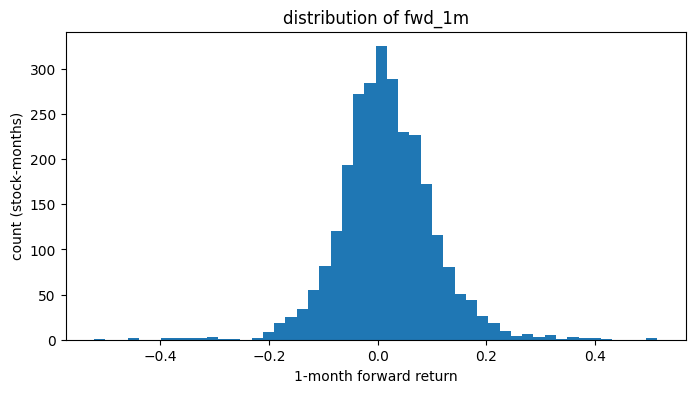

In [10]:
print("fwd_1m stats:")
print("mean:", round(labels["fwd_1m"].mean(), 4))
print("std: ", round(labels["fwd_1m"].std(), 4))
print("min: ", round(labels["fwd_1m"].min(), 4))
print("max: ", round(labels["fwd_1m"].max(), 4))
print("non-missing values:", labels["fwd_1m"].notna().sum())

plt.figure(figsize=(8, 4))
plt.hist(labels["fwd_1m"].dropna(), bins=50)
plt.xlabel("1-month forward return")
plt.ylabel("count (stock-months)")
plt.title("distribution of fwd_1m")
plt.show()

## 10. Save labels and benchmark

In [11]:
labels.to_csv(LABELS_PATH, index=False)
benchmark_ew.to_csv(BENCHMARK_PATH, index=False)

print("saved labels to", LABELS_PATH, "rows:", len(labels))
print("saved benchmark to", BENCHMARK_PATH, "rows:", len(benchmark_ew))

saved labels to ../data/processed/labels.csv rows: 2760
saved benchmark to ../data/processed/benchmark_ew.csv rows: 92
